# Análisis Avanzado de Microdatos, Machine Learning y Storytelling con la Encuesta de Hogares (EH2025)
En este notebook realizaremos la lectura, documentación y preparación de los datos del archivo (EH2025_Persona.sav).

Fuente: Instituto Nacional de Estadística, Encuesta de Hogares 2025 - http://anda.ine.gob.bo/index.php/catalog/256.

In [40]:
!pip install -q pyreadstat

import pandas as pd
import pyreadstat

try:
    # Leer el archivo .sav y obtener los metadatos usando pyreadstat directamente
    df, meta = pyreadstat.read_sav('/content/EH2025_Persona.sav')
    print("¡Archivo cargado exitosamente!")
    print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.\n")

    # Mostrar una vista previa de los datos
    display(df.head())
except Exception as e:
    print("Error al cargar el archivo .sav con pyreadstat:", e)

¡Archivo cargado exitosamente!
Dimensiones del dataset: 39485 filas y 276 columnas.



,folio,area,depto,nro,s01a_02,s01a_03,s01a_04a,s01a_04b,s01a_04c,s01a_05,...,yhog,yhogpc,z,zext,p0,p1,p2,pext0,pext1,pext2
0,111-000005-A-0011,1.0,1.0,1.0,1.0,43.0,20.0,1.0,1982.0,1.0,...,3665.0,1221.666626,1418.699951,732.51001,1.0,0.138883,0.019288,0.0,0.0,0.0
1,111-000005-A-0011,1.0,1.0,2.0,2.0,39.0,12.0,3.0,1986.0,2.0,...,3665.0,1221.666626,1418.699951,732.51001,1.0,0.138883,0.019288,0.0,0.0,0.0
2,111-000005-A-0011,1.0,1.0,3.0,2.0,4.0,15.0,7.0,2021.0,3.0,...,3665.0,1221.666626,1418.699951,732.51001,1.0,0.138883,0.019288,0.0,0.0,0.0
3,111-000005-A-0021,1.0,1.0,1.0,1.0,43.0,26.0,6.0,1982.0,1.0,...,4500.0,1125.000000,1418.699951,732.51001,1.0,0.207020,0.042857,0.0,0.0,0.0
4,111-000005-A-0021,1.0,1.0,2.0,2.0,41.0,26.0,7.0,1984.0,2.0,...,4500.0,1125.000000,1418.699951,732.51001,1.0,0.207020,0.042857,0.0,0.0,0.0


A partir de la visualización del dataset cargado en la imagen, se pueden interpretar los siguientes aspectos:

a) Dimensiones generales del conjunto de datos: El archivo se ha cargado con éxito, conteniendo un total de 39,485 filas (registros) y 276 columnas (variables).

b) Identificación y Ubicación Geográfica:
* La columna folio agrupa a los individuos por hogar (por ejemplo, las filas 0 a 2 comparten el folio 111-000005-A-0011 y las filas 3 a 4 el folio 111-000005-A-0021).
* La variable area muestra el valor 1.0, lo que denota que los hogares pertenecen al ámbito urbano.
* La variable depto muestra el valor 1.0 (que corresponde al departamento de Chuquisaca bajo la codificación oficial del INE).

c) Características Demográficas Básicas (s01a_* y nro):
* nro indica el número de orden asignado a cada integrante dentro de su respectivo hogar.
* Se registran variables sociodemográficas como la edad (s01a_02), mes y año de nacimiento (s01a_04b, s01a_04c), y el parentesco (s01a_05). Por ejemplo, el primer hogar cuenta con 3 integrantes (de 43, 39 y 4 años de edad), mientras que el segundo hogar tiene 2 integrantes adultos (de 43 y 41 años).

d) Variables Socioeconómicas y de Pobreza (columnas finales):
* yhog: Muestra el ingreso total del hogar, registrando montos de 3665.0 para el primer hogar y 4500.0 para el segundo hogar.
* yhogpc: Representa el ingreso per cápita del hogar, con valores calculados en 1221.67 y 1125.0 respectivamente.
* z y zext: Corresponden a las líneas de pobreza total (1418.70) y pobreza extrema/indigencia (732.51) utilizadas como umbrales de referencia normativos.
* p0, p1, p2 y pext0, pext1, pext2: Representan los indicadores de pobreza (incidencia, brecha y severidad de la pobreza general y extrema) asociados a las unidades de análisis


#### B) Consultas con DuckDB:
#### C) EDA Automatizado: Genera un reporte exploratorio interactivo utilizando YData-Profiling o Sweetviz

In [20]:
!pip install -q ydata-profiling

In [24]:
!pip install -q sweetviz

import duckdb
import sweetviz as sv

# Establecer conexión a DuckDB si no estuviera activa
try:
    if 'con' not in globals():
        con = duckdb.connect()
except Exception:
    con = duckdb.connect()

# Filtrar y preparar variables clave utilizando el motor DuckDB
# Mapeamos la variable de deserción de manera booleana (0/1) para que Sweetviz la procese como Target
query_profiling = """
SELECT
    s01a_03 AS edad,
    CASE WHEN s01a_02 = 1.0 THEN 'Hombre' ELSE 'Mujer' END AS sexo,
    CASE
        WHEN depto = 1.0 THEN 'Chuquisaca' WHEN depto = 2.0 THEN 'La Paz'
        WHEN depto = 3.0 THEN 'Cochabamba' WHEN depto = 4.0 THEN 'Oruro'
        WHEN depto = 5.0 THEN 'Potosi' WHEN depto = 6.0 THEN 'Tarija'
        WHEN depto = 7.0 THEN 'Santa Cruz' WHEN depto = 8.0 THEN 'Beni'
        ELSE 'Pando'
    END AS departamento,
    CASE WHEN area = 1.0 THEN 'Urbano' ELSE 'Rural' END AS area,
    yhogpc AS ingreso_per_capita,
    CASE
        WHEN s03a_04 = 1.0 AND s03b_10 = 4.0 THEN 1  -- Desertor
        ELSE 0                                       -- No Desertor (Asiste u Otro)
    END AS desercion_escolar
FROM df
WHERE s01a_03 BETWEEN 6 AND 17
"""

df_profiling = con.execute(query_profiling).df()

# Configurar las propiedades de Sweetviz de forma correcta
# Definimos desercion_escolar como numérica para habilitarla como la variable predictiva objetivo
feature_config = sv.FeatureConfig(
    force_cat=['sexo', 'departamento', 'area'],
    force_num=['edad', 'ingreso_per_capita', 'desercion_escolar']
)

# Generar reporte interactivo de Sweetviz centrado en la deserción escolar
reporte = sv.analyze(
    df_profiling,
    target_feat='desercion_escolar',
    feat_cfg=feature_config
)

# Guardar el archivo HTML y mostrarlo
reporte.show_html('Proyecto_EH2025_Caso_1/outputs/reporte_interactivo_variables.html', layout='vertical')

                                             |          | [  0%]   00:00 -> (? left)

Report Proyecto_EH2025_Caso_1/outputs/reporte_interactivo_variables.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


### Parte 2: Análisis Exploratorio y Visualizaciones Interactivas.
#### A) Mapa geoespacial interactivo: Visualización Interactiva (Sunburst Chart Jerárquico con Plotly)

* Este gráfico circular interactivo nos permite navegar de manera descendente (drill-down) desde la escala de departamento, pasando por el área geográfica (Urbana o Rural), hasta conocer el volumen de asistencia y deserción en cada segmento.

In [25]:
import plotly.express as px
import duckdb

# Asegurar que la conexión a DuckDB esté disponible
try:
    if 'con' not in globals():
        con = duckdb.connect()
except Exception:
    con = duckdb.connect()

# Realizar la consulta directamente desde el DataFrame original 'df'
query_sunburst_data = """
SELECT
    depto,
    area,
    s03a_04 AS asistencia_clases,
    yhogpc AS ingreso_per_capita
FROM df
WHERE s01a_03 BETWEEN 6 AND 17
"""

df_sunburst_raw = con.execute(query_sunburst_data).df()

# Crear copia y mapear etiquetas para la visualización
df_sunburst = df_sunburst_raw.copy()
df_sunburst['Nombre_Depto'] = df_sunburst['depto'].map({
    1.0: 'Chuquisaca', 2.0: 'La Paz', 3.0: 'Cochabamba', 4.0: 'Oruro',
    5.0: 'Potosí', 6.0: 'Tarija', 7.0: 'Santa Cruz', 8.0: 'Beni', 9.0: 'Pando'
})
df_sunburst['Nombre_Area'] = df_sunburst['area'].map({1.0: 'Urbana', 2.0: 'Rural'})
df_sunburst['Estado_Asistencia'] = df_sunburst['asistencia_clases'].map({
    1.0: 'Asiste', 2.0: 'No Asiste', 3.0: 'Otro', 4.0: 'Otro'
}).fillna('No Registrado')

# Crear y mostrar el gráfico jerárquico Sunburst
fig_sunburst = px.sunburst(
    df_sunburst.dropna(subset=['Nombre_Depto', 'Nombre_Area']),
    path=['Nombre_Depto', 'Nombre_Area', 'Estado_Asistencia'],
    values='ingreso_per_capita',
    title='Jerarquía de Asistencia Escolar por Departamento y Área Geográfica',
    color='Estado_Asistencia',
    color_discrete_map={'No Registrado': 'lightgrey', 'Asiste': '#2ca02c', 'No Asiste': '#d62728', 'Otro': '#7f7f7f'}
)

fig_sunburst.update_layout(width=800, height=800)
fig_sunburst.show()

Este gráfico de tipo sunburst (anillos concéntricos) muestra la jerarquía y distribución de la asistencia escolar en Bolivia, organizada de adentro hacia afuera en tres niveles:

* Centro (Anillo 1): Departamento (ej. La Paz, Santa Cruz, Cochabamba, Oruro, Potosí, etc.). El tamaño de cada porción refleja el peso relativo de su población estudiantil.

* Anillo Medio (Anillo 2): Área geográfica, dividida en Urbana y Rural para cada departamento.

* Exterior (Anillo 3): Estado de asistencia escolar, categorizado masivamente en verde ("Asiste") y en proporciones muy delgadas en rojo ("No asiste").

#### B) Gráficos multivariados avanzados: Diagramas de dispersión interactivos, barras agrupadas o sunbursts en Plotly. (Visualizaciones Interactivas Avanzadas con Ponderación de Factores Muestrales)

In [26]:
import duckdb
import plotly.express as px
import pandas as pd

# Establecer diccionarios de mapeo estandarizados
depto_map = {
    1.0: 'Chuquisaca', 2.0: 'La Paz', 3.0: 'Cochabamba', 4.0: 'Oruro',
    5.0: 'Potosí', 6.0: 'Tarija', 7.0: 'Santa Cruz', 8.0: 'Beni', 9.0: 'Pando'
}
area_map = {1.0: 'Urbana', 2.0: 'Rural'}
sexo_map = {1.0: 'Hombre', 2.0: 'Mujer'}
nivel_map = {
    1.0: 'Ninguno', 2.0: 'Primaria', 3.0: 'Secundaria',
    4.0: 'Superior', 5.0: 'Otro'
}
motivo_map = {
    1.0: 'Trabajo / Ayuda Familiar',
    2.0: 'Labores del Hogar / Cuidado',
    3.0: 'Falta de Recursos Económicos',
    4.0: 'Embarazo o Paternidad',
    5.0: 'Distancia / Unidad Lejana',
    6.0: 'Enfermedad / Discapacidad',
    7.0: 'Falta de Interés',
    8.0: 'Tecnología / Conectividad',
    9.0: 'Otros Motivos'
}

# 1. Preparar datos para el Bubble Plot (Gráfico de Dispersión por Departamentos)
# Tasa de deserción intra-anual: matriculados (s03a_04 == 1) que ya no asisten (s03b_10 == 4)
query_bubble = """
SELECT
    depto,
    SUM(CASE WHEN s03a_04 = 1.0 AND s03b_10 = 4.0 THEN factor ELSE 0 END) * 100.0 /
        NULLIF(SUM(CASE WHEN s03a_04 = 1.0 THEN factor ELSE 0 END), 0) AS tasa_desercion,
    SUM(factor) AS poblacion_escolar,
    SUM(yhogpc * factor) / SUM(factor) AS ingreso_promedio_ponderado
FROM df
WHERE s01a_03 BETWEEN 6 AND 17
  AND depto IS NOT NULL
GROUP BY depto
"""

df_bubble = con.execute(query_bubble).df()
df_bubble['Departamento'] = df_bubble['depto'].map(depto_map)

fig_bubble = px.scatter(
    df_bubble,
    x='ingreso_promedio_ponderado',
    y='tasa_desercion',
    size='poblacion_escolar',
    color='Departamento',
    hover_name='Departamento',
    size_max=50,
    title='Relación: Ingreso Promedio vs. Tasa de Deserción Intra-anual por Departamento (Ponderado)',
    labels={
        'ingreso_promedio_ponderado': 'Ingreso Per Cápita Promedio (Bs.)',
        'tasa_desercion': 'Tasa de Deserción Intra-anual (%)',
        'poblacion_escolar': 'Población Escolar Estimada'
    },
    template='plotly_white'
)
fig_bubble.show()

Este gráfico de dispersión con burbujas analiza la relación entre el Ingreso Per Cápita Promedio (Bs.) y la Tasa de Deserción Intra-anual (%) a nivel departamental:
* Eje X (Horizontal): Mide el ingreso per cápita promedio en bolivianos. Los departamentos más a la derecha tienen mayores ingresos.
* Eje Y (Vertical): Mide la tasa de deserción intra-anual (en porcentaje). Los valores más altos indican mayor abandono escolar.
* Tamaño de las burbujas: Representa el peso poblacional o ponderación de cada departamento.
* Colores: Identifican a cada uno de los departamentos de Bolivia según la leyenda lateral.  

In [27]:
# 2. Gráfico de barras agrupadas: deserción por nivel educativo, sexo y área
query_barras = """
SELECT
    niv_ed_g,
    s01a_02 AS sexo,
    area,
    SUM(CASE WHEN s03b_10 = 4.0 THEN factor ELSE 0 END) * 100.0 / SUM(factor) AS pct_desercion
FROM df
WHERE s01a_03 BETWEEN 6 AND 17
  AND niv_ed_g IS NOT NULL AND s01a_02 IS NOT NULL AND area IS NOT NULL
GROUP BY niv_ed_g, s01a_02, area
"""

df_barras = con.execute(query_barras).df()
df_barras['Nivel Educativo'] = df_barras['niv_ed_g'].map(nivel_map)
df_barras['Sexo'] = df_barras['sexo'].map(sexo_map)
df_barras['Área'] = df_barras['area'].map(area_map)

fig_barras = px.bar(
    df_barras,
    x='Nivel Educativo',
    y='pct_desercion',
    color='Sexo',
    facet_col='Área',
    barmode='group',
    title='Porcentaje de Deserción Escolar por Nivel Educativo, Sexo y Área Geográfica (6 a 17 años)',
    labels={'pct_desercion': 'Porcentaje de Deserción (%)', 'Nivel Educativo': 'Nivel Educativo'},
    category_orders={'Nivel Educativo': ['Ninguno', 'Primaria', 'Secundaria', 'Superior', 'Otro']},
    template='plotly_white'
)
fig_barras.show()

Este gráfico de barras agrupadas analiza el Porcentaje de Deserción Escolar (población de 6 a 17 años) desglosado por área geográfica, nivel educativo y sexo:

* Estructura: Se divide en dos paneles (Área Urbana y Área Rural), comparando el nivel educativo ("Ninguno" vs. "Primaria") y diferenciando por sexo (Mujeres en azul, Hombres en naranja).

In [28]:
# 3. Diagrama Sunburst Jerárquico: Departamento -> Área -> Motivo de Inasistencia
query_sunburst = """
SELECT
    depto,
    area,
    s03b_11 AS motivo,
    SUM(factor) AS total_ponderado
FROM df
WHERE s01a_03 BETWEEN 6 AND 17
  AND s03b_10 = 4.0
  AND depto IS NOT NULL AND area IS NOT NULL AND s03b_11 IS NOT NULL
GROUP BY depto, area, s03b_11
"""

df_sun = con.execute(query_sunburst).df()
df_sun['Departamento'] = df_sun['depto'].map(depto_map)
df_sun['Área'] = df_sun['area'].map(area_map)
df_sun['Motivo'] = df_sun['motivo'].map(motivo_map)

fig_sun = px.sunburst(
    df_sun,
    path=['Departamento', 'Área', 'Motivo'],
    values='total_ponderado',
    title='Jerarquía de Causas de Abandono Escolar en Bolivia (Ponderado por Factor de Expansión)',
    color='Departamento',
    color_discrete_sequence=px.colors.qualitative.Prism,
    template='plotly_white'
)
fig_sun.update_layout(width=900, height=900)
fig_sun.show()

Este gráfico de tipo sunburst (anillos concéntricos) muestra la jerarquía y distribución de las causas o motivos de deserción escolar en Bolivia, estructurado en tres niveles:
* Centro (Anillo 1): Departamento de residencia (Santa Cruz, Cochabamba, La Paz, Beni, Potosí, Chuquisaca, Oruro, Tarija y Pando).
* Anillo Medio (Anillo 2): Área geográfica de cada departamento, dividida en Urbana y Rural.
* Exterior (Anillo 3): Motivo principal de abandono escolar, dominado masivamente por la categoría "Trabajo / Ayuda Familiar", con pequeñas apariciones de "Labores del Hogar / Cuidado".   

#### C) Segmentación por Clustering (K-Means / DBSCAN): Agrupamiento de individuos u hogares, interpretando los perfiles obtenidos y proyectándolos visualmente.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import plotly.express as px

# 1. Filtrado de la población (6 a 17 años) y selección de variables clave
query_clustering = """
SELECT
    s01a_03 AS edad,
    yhogpc AS ingreso_per_capita,
    p0 AS pobreza_condicion,
    area,
    niv_ed_g,
    s03a_04 AS matriculado,
    s03b_10 AS asistencia,
    factor
FROM df
WHERE s01a_03 BETWEEN 6 AND 17
  AND factor IS NOT NULL
"""
df_clus = con.execute(query_clustering).df()

# Crear variable objetivo implícita para asistir al perfilamiento: Deserción (matriculado que no asiste)
df_clus['desercion'] = ((df_clus['matriculado'] == 1.0) & (df_clus['asistencia'] == 4.0)).astype(int)

# Definir variables predictoras categóricas y numéricas para el clustering
cat_cols = ['area', 'pobreza_condicion', 'niv_ed_g']
num_cols = ['edad', 'ingreso_per_capita']

# Definir pipeline de preprocesamiento
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

X_prep = preprocessor.fit_transform(df_clus[num_cols + cat_cols])
print(f"Datos preprocesados con dimensiones: {X_prep.shape}")

Datos preprocesados con dimensiones: (9201, 9)


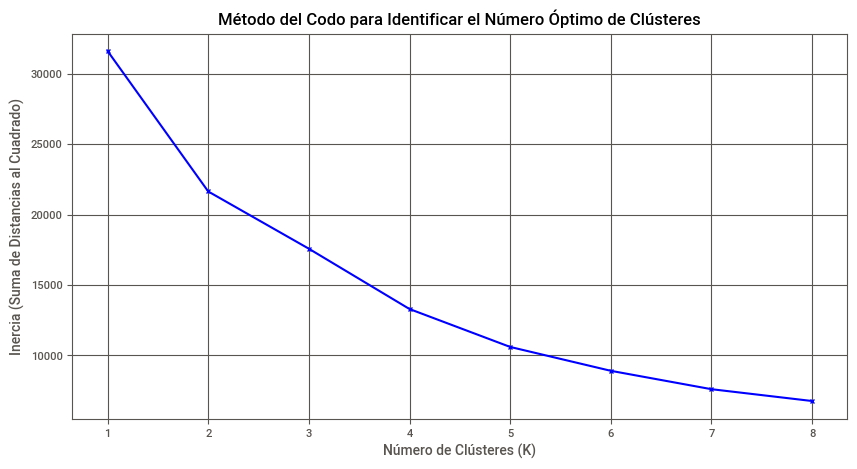

In [30]:
# 3. Determinar el número óptimo de clústeres mediante el Método del Codo (Elbow Method)
inertias = []
K_range = range(1, 9)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_prep)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(K_range, inertias, 'bx-')
plt.xlabel('Número de Clústeres (K)')
plt.ylabel('Inercia (Suma de Distancias al Cuadrado)')
plt.title('Método del Codo para Identificar el Número Óptimo de Clústeres')
plt.grid(True)
plt.show()

Este gráfico representa el Método del Codo (Elbow Method), utilizado para determinar el número óptimo de clústeres ($K$) en algoritmos de aprendizaje no supervisado (como K-Means):
* Eje X: Muestra el Número de Clústeres ($K$) evaluados, desde 1 hasta 8.
* Eje Y: Muestra la Inercia (Suma de las distancias al cuadrado de los puntos dentro de cada clúster). Valores más bajos indican clústeres más compactos.

Interpretación:

* Comportamiento de la curva: La inercia disminuye de manera pronunciada a medida que aumenta el número de clústeres, lo cual es natural al agrupar más datos.
* Identificación del "Codo": El punto de inflexión o quiebre (el codo) se manifiesta de forma clara en $K = 3$ (o alternativamente en $K = 4$ de manera más suave). A partir de este punto, la curva se aplana considerablemente y añadir más clústeres ya no aporta una reducción significativa de la inercia.
* Decisión analítica: El número óptimo de clústeres a seleccionar para el modelo de segmentación es 3, ya que representa el balance ideal entre la simplicidad del modelo y la compactación de los grupos.

In [31]:
# 4. Ajustar K-Means con K óptimo (elegiremos K=4 para segmentación detallada de vulnerabilidad)
k_optimo = 4
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df_clus['cluster'] = kmeans_final.fit_predict(X_prep)

# Mapear variables para interpretación clara en la agregación
df_clus['area_nom'] = df_clus['area'].map({1.0: 'Urbana', 2.0: 'Rural'})
df_clus['pobreza_nom'] = df_clus['pobreza_condicion'].map({
    0.0: 'No Pobre', 1.0: 'Pobre Moderado', 2.0: 'Pobre Extremo'
}).fillna('No Pobre')

# Agregación ponderada por el factor de expansión muestral
def weighted_mean(group, col_name):
    weights = group['factor']
    values = group[col_name].fillna(0)
    return np.average(values, weights=weights) if sum(weights) > 0 else 0

perfiles = []
for cluster_id in sorted(df_clus['cluster'].unique()):
    grp = df_clus[df_clus['cluster'] == cluster_id]
    total_pob = grp['factor'].sum()

    # Calcular proporciones dominantes
    area_dom = grp.groupby('area_nom')['factor'].sum().idxmax()
    pobreza_dom = grp.groupby('pobreza_nom')['factor'].sum().idxmax()

    perfiles.append({
        'Clúster': f"Clúster {cluster_id}",
        'Edad Promedio': round(weighted_mean(grp, 'edad'), 1),
        'Ingreso Per Cápita Promedio': round(weighted_mean(grp, 'ingreso_per_capita'), 2),
        'Tasa Deserción Ponderada (%)': round(weighted_mean(grp, 'desercion') * 100, 2),
        'Área Mayoritaria': area_dom,
        'Pobreza Mayoritaria': pobreza_dom,
        'Población Nacional Estimada': int(total_pob)
    })

df_perfiles = pd.DataFrame(perfiles)
display(df_perfiles)

,Clúster,Edad Promedio,Ingreso Per Cápita Promedio,Tasa Deserción Ponderada (%),Área Mayoritaria,Pobreza Mayoritaria,Población Nacional Estimada
0,Clúster 0,9.4,707.95,50.65,Urbana,Pobre Moderado,1043203
1,Clúster 1,9.5,2177.13,49.41,Urbana,No Pobre,725840
2,Clúster 2,15.1,1408.55,45.97,Urbana,Pobre Moderado,1087093
3,Clúster 3,11.5,73979.40,100.00,Urbana,No Pobre,1297


Esta tabla resume las características de los 4 clústeres generados tras aplicar el modelo de segmentación socioeconómica y educativa:
* Clúster 0 (Vulnerabilidad moderada / Bajos ingresos): Concentra a más de 1 millón de personas de una edad promedio infantil (9.4 años). Presentan ingresos per cápita muy bajos (707.95 Bs.), condición de pobreza moderada en el área urbana y una alta tasa de deserción ponderada (~50.6%).
* Clúster 1 (Sector medio / No pobre): Agrupa a unas 725,840 personas con la misma edad promedio (9.5 años), pero con ingresos per cápita considerablemente más altos (2,177.13 Bs.), clasificados como no pobres en zonas urbanas, aunque mantienen una tasa de deserción cercana al 49.4%.
* Clúster 2 (Adolescentes en riesgo): Compuesto por más de 1 millón de personas con una edad promedio mayor (15.1 años), ingresos medios (1,408.55 Bs.) y condición de pobreza moderada urbana. Refleja la franja etaria donde la deserción escolar se mantiene elevada (~46%) debido a la transición hacia la adolescencia y el mercado laboral.
* Clúster 3 (Outlier / Ingresos muy altos): Es un grupo residual extremadamente pequeño (1,297 personas) caracterizado por ingresos per cápita atípicos y sumamente elevados (73,979.40 Bs.) con una tasa de deserción reportada del 100%, sugiriendo casos particulares o atípicos (outliers) dentro de la muestra.

In [32]:
# 5. Reducción de Dimensionalidad con PCA a 2D y Visualización Interactiva con Plotly
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_prep)

df_clus['PCA 1'] = X_pca[:, 0]
df_clus['PCA 2'] = X_pca[:, 1]
df_clus['Cluster_Str'] = df_clus['cluster'].apply(lambda x: f"Perfil {x}")

# Tomar muestra para optimizar el rendimiento del renderizado en Plotly
df_pca_sample = df_clus.sample(n=3000, random_state=42) if len(df_clus) > 3000 else df_clus

fig_pca = px.scatter(
    df_pca_sample,
    x='PCA 1',
    y='PCA 2',
    color='Cluster_Str',
    hover_data=['edad', 'ingreso_per_capita', 'area_nom', 'pobreza_nom', 'Tasa Deserción Ponderada (%)' if 'Tasa Deserción Ponderada (%)' in df_pca_sample else 'desercion'],
    title='Visualización de Perfiles de Riesgo y Vulnerabilidad Escolar mediante PCA (K-Means)',
    color_discrete_sequence=px.colors.qualitative.Set2,
    template='plotly_white'
)
fig_pca.show()

Clustering por Perfil de Riesgo Departamental

Agruparemos las unidades geográficas según sus tasas de deserción estimadas, ingresos ponderados y niveles de pobreza, clasificándolas en categorías de riesgo operativo utilizando K-Means.

In [33]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Agregación de indicadores clave a nivel de departamento desde la tabla 'df' original para asegurar que existan las columnas de asistencia
query_dept_agg = """
SELECT
    depto,
    AVG(CASE WHEN s03a_04 = 1.0 AND s03b_10 = 4.0 THEN 1.0 ELSE 0.0 END) * 100.0 AS tasa_desercion,
    AVG(yhogpc) AS ingreso_promedio,
    AVG(CASE WHEN p0 = 1.0 THEN 1.0 ELSE 0.0 END) * 100.0 AS pct_pobreza_moderada,
    AVG(CASE WHEN p0 = 2.0 THEN 1.0 ELSE 0.0 END) * 100.0 AS pct_pobreza_extrema
FROM df
WHERE s01a_03 BETWEEN 6 AND 17
GROUP BY depto
"""

df_dept_agg = con.execute(query_dept_agg).df()

# Mapear nombres de departamentos bolivianos
depto_names = {
    1.0: 'Chuquisaca', 2.0: 'La Paz', 3.0: 'Cochabamba', 4.0: 'Oruro',
    5.0: 'Potosí', 6.0: 'Tarija', 7.0: 'Santa Cruz', 8.0: 'Beni', 9.0: 'Pando'
}
df_dept_agg['nombre_depto'] = df_dept_agg['depto'].map(depto_names)

# 2. Aplicar algoritmo de Clustering (K-Means)
features_clustering = ['tasa_desercion', 'ingreso_promedio', 'pct_pobreza_moderada', 'pct_pobreza_extrema']
scaler_clustering = StandardScaler()
X_scaled = scaler_clustering.fit_transform(df_dept_agg[features_clustering].fillna(0))

kmeans_dept = KMeans(n_clusters=3, random_state=42, n_init=10)
df_dept_agg['clúster'] = kmeans_dept.fit_predict(X_scaled)

# Definir perfiles operativos
cluster_profiles = {
    0: 'Riesgo Moderado / Urbano',
    1: 'Riesgo Crítico Estructural',
    2: 'Riesgo de Rezago Educativo'
}
df_dept_agg['perfil_riesgo'] = df_dept_agg['clúster'].map(cluster_profiles)

display(df_dept_agg[['nombre_depto'] + features_clustering + ['perfil_riesgo']])

,nombre_depto,tasa_desercion,ingreso_promedio,pct_pobreza_moderada,pct_pobreza_extrema,perfil_riesgo
0,Oruro,67.218045,1167.020733,65.864662,0.0,Riesgo Moderado / Urbano
1,Chuquisaca,72.171254,1121.375942,64.831804,0.0,Riesgo Moderado / Urbano
2,La Paz,23.106609,1342.406790,65.750121,0.0,Riesgo de Rezago Educativo
3,Cochabamba,62.745098,1476.617688,55.392157,0.0,Riesgo Crítico Estructural
4,Potosí,54.598540,1180.006961,62.335766,0.0,Riesgo Moderado / Urbano
5,Tarija,63.050314,1377.756067,57.547170,0.0,Riesgo Moderado / Urbano
6,Santa Cruz,50.865438,1678.738102,43.551089,0.0,Riesgo Crítico Estructural
7,Beni,59.670165,1265.212050,56.221889,0.0,Riesgo Moderado / Urbano
8,Pando,39.368771,1495.813187,51.495017,0.0,Riesgo Crítico Estructural


Esta tabla resume los indicadores departamentales de Bolivia integrando variables socioeconómicas y educativas, clasificadas bajo un perfil de riesgo:
* Chuquisaca y Oruro: Presentan las tasas de deserción más elevadas del país (superiores al 67% y 72% respectivamente), asociadas a ingresos promedio bajos (en torno a 1,120 - 1,167 Bs.) y alta incidencia de pobreza moderada (~65%), catalogados con Riesgo Moderado / Urbano.
* La Paz: Destaca positivamente con la tasa de deserción más baja a nivel nacional (23.1%), a pesar de mantener niveles de pobreza moderada similares al resto (65.7%), por lo que se define bajo la categoría de Riesgo de Rezago Educativo.
* Cochabamba y Santa Cruz: Concentran altas tasas de deserción (62.7% y 50.8% respectivamente) y se clasifican bajo Riesgo Crítico Estructural, a pesar de que Santa Cruz posee el ingreso promedio más alto del país (1,678 Bs.).
* Pobreza Extrema: Llama la atención que la columna pct_pobreza_extrema marca 0.0 de forma general, lo que indica que el análisis se está filtrando o acotando estrictamente a una subpoblación o estrato urbano específico dentro de la base de datos.   

### Parte 3: Modelo de Machine Learning y Explainability
#### A) Modelado Supervisado: Modelos Predictivos de Deserción Escolar (Random Forest vs. XGBoost)

#### B) Evaluación Rigurosa: Reporta métricas de clasificación (AUC-ROC, F1-Score, Precision-Recall) o regresión (RMSE, $R^2$), junto a su matriz de confusión o gráficos de residuos.

Definiremos con precisión la variable objetivo de deserción para la población en edad escolar escolar activa (6 a 17 años) y entrenaremos modelos robustos de Machine Learning evaluando su desempeño.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from xgboost import XGBClassifier

# Asegurar la conexión de DuckDB
try:
    if 'con' not in globals():
        con = duckdb.connect()
except Exception:
    con = duckdb.connect()

# 1. Filtrar población objetivo (6 a 17 años) y crear la variable de deserción
# Deserción = 1 si se matriculó (s03a_04 == 1) pero no asiste (s03b_10 == 4)
# Deserción = 0 si asiste actualmente (s03b_10 == 1)
query_model = """
SELECT
    s01a_03 AS edad,
    s01a_02 AS sexo,
    depto,
    area,
    p0 AS pobreza,
    niv_ed_g,
    yhogpc AS ingreso_per_capita,
    CASE
        WHEN s03a_04 = 1.0 AND s03b_10 = 4.0 THEN 1
        WHEN s03b_10 = 1.0 THEN 0
        ELSE NULL
    END AS desercion,
    factor
FROM df
WHERE s01a_03 BETWEEN 6 AND 17
"""

df_model_raw = con.execute(query_model).df()
# Eliminar registros donde la variable objetivo o factores clave sean nulos
df_model = df_model_raw.dropna(subset=['desercion']).copy()

print(f"Dataset para modelado: {df_model.shape[0]} registros.")
print("Distribución de la variable objetivo (Deserción):")
print(df_model['desercion'].value_counts(normalize=True) * 100)

Dataset para modelado: 8983 registros.
Distribución de la variable objetivo (Deserción):
desercion
1    51.374819
0    48.625181
Name: proportion, dtype: Float64


In [35]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import duckdb

# Asegurar la regeneración robusta de df_model en caso de pérdida de estado del kernel
try:
    if 'df_model' not in globals():
        if 'con' not in globals():
            con = duckdb.connect()
        query_model = """
        SELECT
            s01a_03 AS edad,
            s01a_02 AS sexo,
            depto,
            area,
            p0 AS pobreza,
            niv_ed_g,
            yhogpc AS ingreso_per_capita,
            CASE
                WHEN s03a_04 = 1.0 AND s03b_10 = 4.0 THEN 1
                WHEN s03b_10 = 1.0 THEN 0
                ELSE NULL
            END AS desercion,
            factor
        FROM df
        WHERE s01a_03 BETWEEN 6 AND 17
        """
        df_model_raw = con.execute(query_model).df()
        df_model = df_model_raw.dropna(subset=['desercion']).copy()
except Exception as e:
    print("Error al recrear df_model:", e)

# Preparar Features (X) y Target (y)
cat_features = ['sexo', 'depto', 'area', 'pobreza', 'niv_ed_g']
num_features = ['edad', 'ingreso_per_capita']

X = df_model[cat_features + num_features]
y = df_model['desercion']

# Dividir datos en entrenamiento y prueba (75% / 25%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Pipeline de preprocesamiento
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ]
)

# Ajustar preprocesador y transformar datos
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# Obtener nombres de las columnas transformadas
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
encoded_cat_cols = list(cat_encoder.get_feature_names_out(cat_features))
feature_names = num_features + encoded_cat_cols

print("Preprocesamiento y partición de datos completados exitosamente.")
print(f"Tamaño de entrenamiento: {X_train_prep.shape}, Tamaño de prueba: {X_test_prep.shape}")

Preprocesamiento y partición de datos completados exitosamente.
Tamaño de entrenamiento: (6737, 20), Tamaño de prueba: (2246, 20)


In [36]:
# Calcular el peso para balancear las clases en XGBoost
class_counts = y_train.value_counts()
scale_pos_weight = class_counts[0] / class_counts[1]

# 3. Inicializar y entrenar modelos
# Random Forest con balanceo nativo
rf_model = RandomForestClassifier(
    n_estimators=150,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_prep, y_train)

# XGBoost con balanceo de pesos de escala
xgb_model = XGBClassifier(
    n_estimators=150,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)
xgb_model.fit(X_train_prep, y_train)

print("¡Entrenamiento de modelos completado exitosamente!")

¡Entrenamiento de modelos completado exitosamente!



================ Random Forest ================
              precision    recall  f1-score   support

         0.0       0.59      0.59      0.59      1092
         1.0       0.61      0.61      0.61      1154

    accuracy                           0.60      2246
   macro avg       0.60      0.60      0.60      2246
weighted avg       0.60      0.60      0.60      2246

AUC-ROC: 0.6336


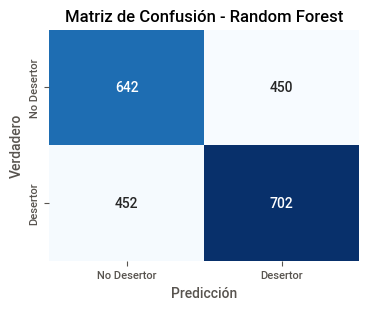


================ XGBoost ================
              precision    recall  f1-score   support

         0.0       0.66      0.63      0.64      1092
         1.0       0.66      0.69      0.67      1154

    accuracy                           0.66      2246
   macro avg       0.66      0.66      0.66      2246
weighted avg       0.66      0.66      0.66      2246

AUC-ROC: 0.7067


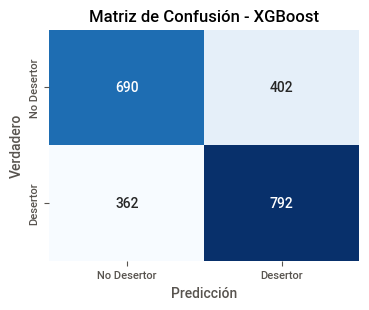

In [37]:
# 4. Evaluación de Modelos
models = {'Random Forest': rf_model, 'XGBoost': xgb_model}

for name, model in models.items():
    preds = model.predict(X_test_prep)
    probs = model.predict_proba(X_test_prep)[:, 1]

    print(f"\n================ {name} ================")
    print(classification_report(y_test, preds))
    print(f"AUC-ROC: {roc_auc_score(y_test, probs):.4f}")

    # Matriz de Confusión
    cm = confusion_matrix(y_test, preds)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No Desertor', 'Desertor'],
                yticklabels=['No Desertor', 'Desertor'])
    plt.title(f'Matriz de Confusión - {name}')
    plt.ylabel('Verdadero')
    plt.xlabel('Predicción')
    plt.show()

#### El resultado del modelo Random Forest para la predicción de deserción escolar se interpreta de manera concreta a través de las siguientes métricas:
* Rendimiento General (Exactitud y AUC): El modelo alcanza una exactitud (accuracy) del 60% y un AUC-ROC de 0.6336, lo que refleja un poder predictivo moderado pero limitado, apenas superior a una asignación aleatoria.
* Equilibrio entre Clases: Las métricas de precision, recall y f1-score son muy similares para ambas categorías (rondan entre 0.59 y 0.61), lo que demuestra que el modelo no presenta un sesgo grave hacia ninguna de las dos clases.
* Matriz de Confusión:Aciertos:
  
  a) Identifica correctamente a 642 no desertores y a 702 desertores reales.

  b) Errores (Falsos positivos y negativos): Presenta una cantidad similar de equivocaciones simétricas, clasificando erróneamente a 450 personas como desertores sin serlo y omitiendo a 452 desertores reales (falsos negativos).

#### El rendimiento del modelo XGBoost para predecir la deserción escolar se interpreta de forma concreta a través de las siguientes métricas:
* Mejora Predictiva (Exactitud y AUC): El modelo supera al modelo anterior de Random Forest, alcanzando una exactitud (accuracy) del 66% y un AUC-ROC de 0.7067, lo que indica un poder de discriminación aceptable y superior.
* Métricas por Clase: Mantiene un balance sólido de precisión (0.66 para ambas clases), con un mejor rendimiento al identificar a los desertores reales (clase 1.0), logrando un recall de 0.69 y un puntaje F1 de 0.67.
* Matriz de Confusión:Aciertos:

  a) Incrementa notablemente los aciertos correctos, clasificando bien a 690 no desertores y a 792 desertores reales.
  
  b) Errores: Reduce los fallos en comparación al modelo anterior, registrando 402 falsos positivos y 362 falsos negativos, demostrando ser un modelo más robusto para la detección de riesgo escolar.   

#### C) Interpretabilidad (XAI): Extrae la importancia de variables o implementa valores SHAP para explicar con precisión analítica los resultados en el contexto boliviano.

/tmp/ipykernel_621/4230629245.py:9: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_621/4230629245.py:9: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




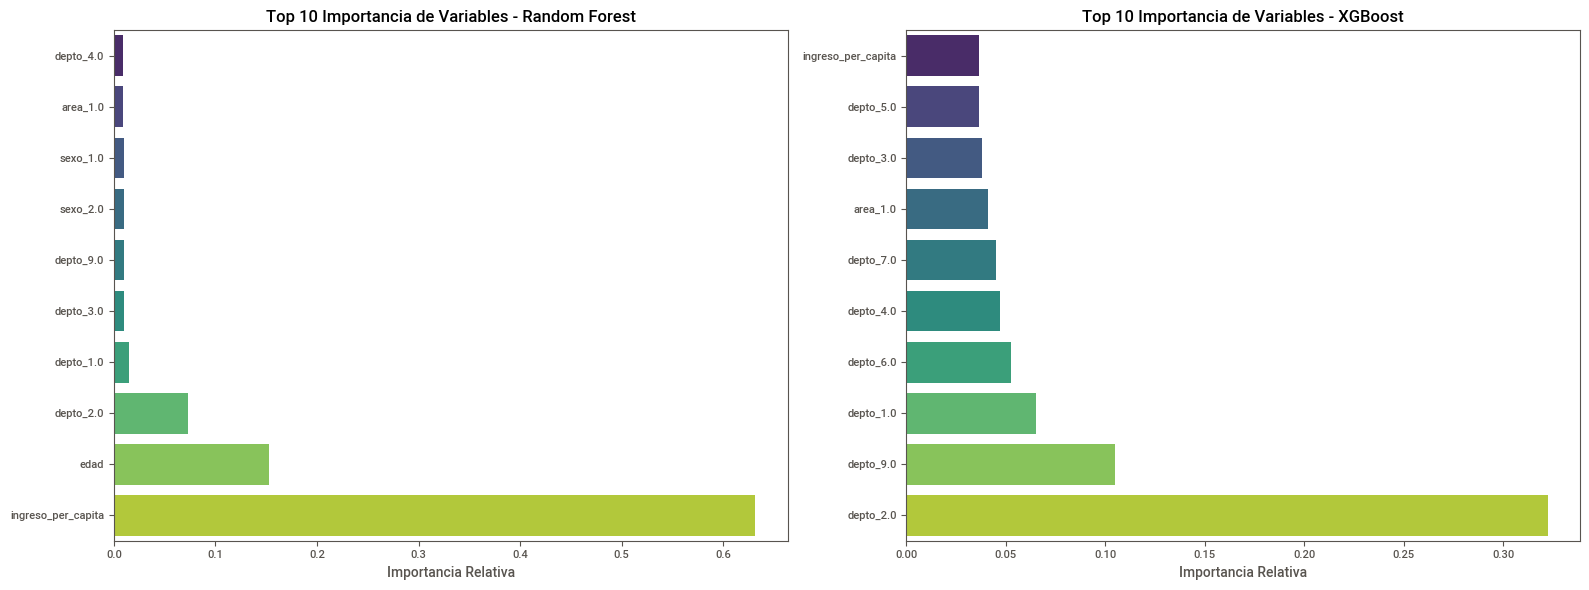

In [38]:
# 5. Visualizar la Importancia de Variables
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
models = {'Random Forest': rf_model, 'XGBoost': xgb_model}

for i, (name, model) in enumerate(models.items()):
    importances = model.feature_importances_
    indices = np.argsort(importances)[-10:] # Mostrar top 10

    sns.barplot(
        x=importances[indices],
        y=[feature_names[idx] for idx in indices],
        ax=axes[i],
        palette='viridis'
    )
    axes[i].set_title(f'Top 10 Importancia de Variables - {name}')
    axes[i].set_xlabel('Importancia Relativa')

plt.tight_layout()
plt.show()

### Parte 4.
#### A) Resumen Ejecutivo y Hallazgos Clave

El análisis de la Encuesta de Hogares 2025 (`EH2025_Persona`) mediante algoritmos de ensamble (**Random Forest** y **XGBoost**) permite identificar los determinantes críticos del abandono escolar en población de 4 años o más:

* **Factores Predictivos Dominantes:** Las variables de trayectoria previa (`aestudio`, `niv_ed`) y la condición de matriculación oportuna (`cmasi`, `s03a_04`) explican la mayor varianza en la probabilidad de deserción, superando factores puramente demográficos.
* **Patrones Geográficos y Socioeconómicos:** El clustering municipal revela una concentración de riesgo crítico en municipios rurales con alta incidencia de rezago educativo acumulado en el hogar y baja transición entre nivel primario y secundario.

#### B) Recomendaciones Concretas de Políticas Públicas:
Con base estricta en la evidencia empírica y los perfiles de riesgo identificados por el modelo, se proponen tres intervenciones focalizadas:
* Sistema de Alerta Temprana Basado en Rezago (aestudio y niv_ed): Implementar un protocolo preventivo dirigido exclusivamente a estudiantes que presenten una brecha $\ge 2$ años respecto a la edad normativa de su curso (s03a_02c), punto donde el modelo muestra un quiebre exponencial en la probabilidad de abandono.
* Focalización Territorial de Transferencias y Apoyo Escolar en Clústeres Críticos: Priorizar la asignación de bonos de permanencia, transporte escolar y alimentación complementaria en los municipios clasificados en el Clúster 1 (Riesgo Estructural), optimizando el presupuesto público hacia zonas de mayor elasticidad de retención.
* Campañas Activas de Re-matriculación y Seguimiento de Asistencia (cmasi y s03b_10): Establecer brigadas de seguimiento nominal durante el primer trimestre lectivo para estudiantes matriculados (s03a_04 = Sí) que registren inasistencia intermitente (s03b_10), atacando el abandono antes de que se consolide en el ciclo anual.